# 06 Marketing funnel (stage 3b): which lead channels bring good sellers?
Olist's marketing funnel dataset: businesses that showed interest in selling on Olist (marketing-qualified leads), where they came from, and which signed up as sellers.

## Step 1. Download and load the data

In [1]:
import os, shutil
import numpy as np
import pandas as pd
import kagglehub

RAW = r"..\data\raw"
FUNNEL = RAW + r"\marketing_funnel"

path = kagglehub.dataset_download("olistbr/marketing-funnel-olist")
os.makedirs(FUNNEL, exist_ok=True)
for f in os.listdir(path):
    shutil.copy(os.path.join(path, f), FUNNEL)

print(os.listdir(FUNNEL))

leads = pd.read_csv(FUNNEL + r"\olist_marketing_qualified_leads_dataset.csv")
deals = pd.read_csv(FUNNEL + r"\olist_closed_deals_dataset.csv")
print(leads.shape, deals.shape)
print(leads.head(3))
print(deals.columns.tolist())

Extracting files...


['olist_closed_deals_dataset.csv', 'olist_marketing_qualified_leads_dataset.csv']
(8000, 4) (842, 14)
                             mql_id first_contact_date  \
0  dac32acd4db4c29c230538b72f8dd87d         2018-02-01   
1  8c18d1de7f67e60dbd64e3c07d7e9d5d         2017-10-20   
2  b4bc852d233dfefc5131f593b538befa         2018-03-22   

                    landing_page_id          origin  
0  88740e65d5d6b056e0cda098e1ea6313          social  
1  007f9098284a86ee80ddeb25d53e0af8     paid_search  
2  a7982125ff7aa3b2054c6e44f9d28522  organic_search  
['mql_id', 'seller_id', 'sdr_id', 'sr_id', 'won_date', 'business_segment', 'lead_type', 'lead_behaviour_profile', 'has_company', 'has_gtin', 'average_stock', 'business_type', 'declared_product_catalog_size', 'declared_monthly_revenue']


## Step 2. First look and coverage check
- Leads per channel and the date range.
- Join leads to deals: a lead "converted" if it has a seller_id.
- Coverage: how many signed sellers appear in the orders data, and with how many orders. This decides whether we can link channels to customer experience.

In [2]:
print("First contact:", leads['first_contact_date'].min(), "to", leads['first_contact_date'].max())
print(leads['origin'].value_counts(dropna=False), "\n")

funnel = leads.merge(deals, on='mql_id', how='left')
funnel['converted'] = funnel['seller_id'].notna()
print("Overall conversion:", round(funnel['converted'].mean() * 100, 2), "%\n")

items = pd.read_csv(RAW + r"\olist_order_items_dataset.csv", usecols=['order_id', 'seller_id'])
seller_orders = items.groupby('seller_id')['order_id'].nunique()

deals['orders_on_olist'] = deals['seller_id'].map(seller_orders).fillna(0)
print("Signed sellers with at least 1 order:", (deals['orders_on_olist'] > 0).sum(), "of", len(deals))
print("Signed sellers with 10+ orders:", (deals['orders_on_olist'] >= 10).sum())
print("Total orders from these sellers:", int(deals['orders_on_olist'].sum()))

First contact: 2017-06-14 to 2018-05-31
origin
organic_search       2296
paid_search          1586
social               1350
unknown              1099
direct_traffic        499
email                 493
referral              284
other                 150
display               118
other_publicities      65
NaN                    60
Name: count, dtype: int64 

Overall conversion: 10.52 %

Signed sellers with at least 1 order: 380 of 842
Signed sellers with 10+ orders: 112
Total orders from these sellers: 4518


## Step 3. Funnel by channel: lead → seller → active seller
- Conversion: share of leads that signed as sellers.
- Activation: share of signed sellers that made at least one sale in the orders data.
- Active per 100 leads: the full funnel in one number.
60 leads with no channel are grouped with "unknown". Channels with few sellers are indicative only.

In [3]:
funnel['origin'] = funnel['origin'].fillna('unknown')
funnel['orders_on_olist'] = funnel['seller_id'].map(seller_orders).fillna(0)
funnel['active'] = funnel['orders_on_olist'] > 0

by_channel = funnel.groupby('origin').agg(
    leads=('mql_id', 'size'),
    sellers=('converted', 'sum'),
    active_sellers=('active', 'sum'),
    orders=('orders_on_olist', 'sum'),
)
by_channel['conversion_pct'] = by_channel['sellers'] / by_channel['leads'] * 100
by_channel['activation_pct'] = by_channel['active_sellers'] / by_channel['sellers'] * 100
by_channel['active_per_100_leads'] = by_channel['active_sellers'] / by_channel['leads'] * 100
by_channel.sort_values('leads', ascending=False).round(1)

,leads,sellers,active_sellers,orders,conversion_pct,activation_pct,active_per_100_leads
origin,,,,,,,
organic_search,2296,271,113,1208.0,11.8,41.7,4.9
paid_search,1586,195,101,1247.0,12.3,51.8,6.4
social,1350,75,31,392.0,5.6,41.3,2.3
unknown,1159,193,85,1291.0,16.7,44.0,7.3
direct_traffic,499,56,31,193.0,11.2,55.4,6.2
email,493,15,6,22.0,3.0,40.0,1.2
referral,284,24,9,69.0,8.5,37.5,3.2
other,150,4,2,89.0,2.7,50.0,1.3
display,118,6,2,7.0,5.1,33.3,1.7


## Step 4. How sure are we? And how fast do channels close?
95% ranges (normal approximation) for conversion and activation in the five largest channels. Overlapping ranges mean the difference may be chance.
Time to close: days from first contact to signed deal.

In [4]:
main = ['organic_search', 'paid_search', 'social', 'unknown', 'direct_traffic']

def ci95(successes, n):
    """Rate and 95% range, in percent."""
    p = successes / n
    margin = 1.96 * np.sqrt(p * (1 - p) / n)
    return round(p * 100, 1), round(max(p - margin, 0) * 100, 1), round((p + margin) * 100, 1)

rows = []
for ch in main:
    r = by_channel.loc[ch]
    c, c_lo, c_hi = ci95(r['sellers'], r['leads'])
    a, a_lo, a_hi = ci95(r['active_sellers'], r['sellers'])
    rows.append({'channel': ch, 'conversion': c, 'conversion_range': f"{c_lo} to {c_hi}",
                 'activation': a, 'activation_range': f"{a_lo} to {a_hi}"})
print(pd.DataFrame(rows), "\n")

won = funnel[funnel['converted']].copy()
won['days_to_close'] = (pd.to_datetime(won['won_date']) - pd.to_datetime(won['first_contact_date'])).dt.days
won.groupby('origin')['days_to_close'].agg(['count', 'median']).loc[main]

          channel  conversion conversion_range  activation activation_range
0  organic_search        11.8     10.5 to 13.1        41.7     35.8 to 47.6
1     paid_search        12.3     10.7 to 13.9        51.8     44.8 to 58.8
2          social         5.6       4.3 to 6.8        41.3     30.2 to 52.5
3         unknown        16.7     14.5 to 18.8        44.0     37.0 to 51.0
4  direct_traffic        11.2      8.5 to 14.0        55.4     42.3 to 68.4 



,count,median
origin,,
organic_search,271,14.0
paid_search,195,15.0
social,75,30.0
unknown,193,11.0
direct_traffic,56,10.0


## Step 5. Is the paid vs organic activation gap real?
Two-proportion z-test: is 51.8% (101 of 195 paid-search sellers) really different from 41.7% (113 of 271 organic sellers)?
A p-value below 0.05 means a gap this large would be unlikely if the true rates were equal.

Gap: 10.1 points | z = 2.16 | p-value = 0.031


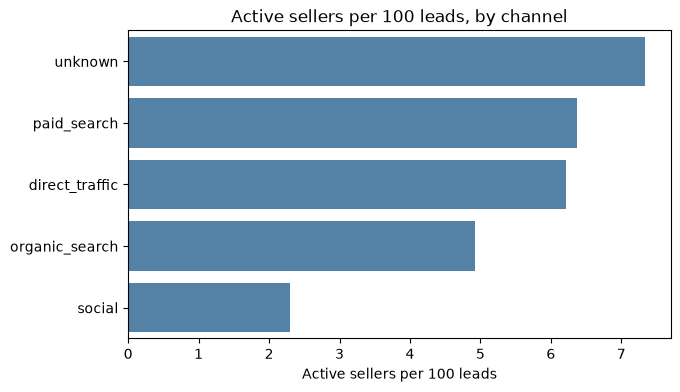

In [5]:
from math import erf, sqrt

a1, n1 = 101, 195   # paid search: active sellers, signed sellers
a2, n2 = 113, 271   # organic search
p1, p2 = a1 / n1, a2 / n2
pooled = (a1 + a2) / (n1 + n2)
z = (p1 - p2) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
p_value = 2 * (1 - 0.5 * (1 + erf(abs(z) / sqrt(2))))
print(f"Gap: {(p1 - p2) * 100:.1f} points | z = {z:.2f} | p-value = {p_value:.3f}")

# Chart: active sellers per 100 leads, main channels
import seaborn as sns
import matplotlib.pyplot as plt

FIG = r"..\reports\figures"
chart = by_channel.loc[main].reset_index().sort_values('active_per_100_leads', ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(data=chart, x='active_per_100_leads', y='origin', color='steelblue')
plt.title('Active sellers per 100 leads, by channel')
plt.xlabel('Active sellers per 100 leads')
plt.ylabel('')
plt.savefig(FIG + r"\s3b_active_per_100_leads.png", dpi=150, bbox_inches='tight')
plt.show()

**Result.** Paid vs organic activation gap: 10.1 points, z = 2.16, p = 0.031. Paid-search sellers are more likely to start selling: modest evidence of a real difference.
**Limit:** the dataset has no cost per lead, so this measures active sellers per lead, not return on spend. Social (2.3 per 100 leads vs 6.4 for paid search) only pays off if its leads cost less than about a third as much.